# K-M 复势点力基本解富集 PIKFNN：II 型中心裂纹
## 四分之一模型：右上区域 $0\le x\le b,\ 0\le y\le h$

本版本由原来的“右半区域 + 上下双子域”改成**单一四分之一域**。

核心变化：

- 只保留右上子域，不再建立 `upper/lower` 两套普通 MFS 系数；
- 裂尖前方韧带直接施加 Mode-II 反对称条件：$u_x=0,\ \sigma_{yy}=0$；
- 左边界施加关于 $x=0$ 的反对称条件：$u_y=0,\ \sigma_{xx}=0$；
- 删除上下界面连续性、镜像配点、裂尖 regular-field continuity 等双子域专用约束；
- 保留原 Mode-II 的 K-M 点力基本解与单位 $K_{II}$ 裂尖渐近富集项；
- 裂尖局部源默认只保留一圈 $r_s=0.08a$，便于与 Mode-I 单圆弧版本公平比较。

In [127]:
import math
import time

import numpy as np
import torch
import torch.nn as nn
import matplotlib.pyplot as plt

# Double precision is strongly recommended for MFS / K-M kernels.
torch.set_default_dtype(torch.float64)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

cfg = {
    # Geometry / material / loading
    "a": 1.0,
    "b": 2.0,
    "h": 6.0,
    "E": 1.0,
    "nu": 0.30,
    "tau0": 1.0,
    "plane_strain": True,

    # Quarter-domain boundary collocation
    "n_top": 121,
    "n_side": 121,
    "n_crack": 120,
    "n_ligament": 120,

    # Geometric refinement around the right crack tip
    "r_min": 1.0e-4,
    "r_transition": 0.20,
    "eps_crack": 1.0e-8,

    # Exterior point-force sources
    "n_src_side": 64,
    "src_margin_x_factor": 0.15,
    "src_margin_y_factor": 0.05,

    # Local MFS source cluster below the crack tip.
    # One ring by default. Change to [0.08, 0.16] to restore two rings.
    "tip_cluster_count": 32,
    "tip_cluster_radii": [0.05],
    "tip_cluster_angle_min_deg": 200.0,
    "tip_cluster_angle_max_deg": 340.0,

    # Optimization
    "adam_steps": 1500,
    "adam_lr": 1.0e-2,
    "lbfgs_epochs": 200,
    "lbfgs_max_iter": 20,
    "adam_print_every": 100,
    "lbfgs_print_every": 20,

    # Boundary loss weights
    "w_top": 2.5,
    "w_right": 1.5,
    "w_left": 2.0,
    "w_crack": 8.0,
    "w_ligament": 6.0,
    "lambda_reg": 1.0e-10,

    # Linear-system diagnostic
    "svd_rtol": 1.0e-10,

    # Plotting
    "nx_plot": 181,
    "ny_plot": 361,
    "seed": 2026,
}

torch.manual_seed(cfg["seed"])
np.random.seed(cfg["seed"])
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(cfg["seed"])

print("device =", device)

device = cuda


## 1. 材料参数与参考 $K_{II}$

远场为纯剪切 $\tau_{xy}=\tau_0$。参考值只用于训练后的误差评估，不进入损失函数。

In [128]:
E = cfg["E"]
nu = cfg["nu"]
a = cfg["a"]
b = cfg["b"]
h = cfg["h"]
tau0 = cfg["tau0"]

mu = E / (2.0 * (1.0 + nu))
if cfg["plane_strain"]:
    kappa = 3.0 - 4.0 * nu
else:
    kappa = (3.0 - nu) / (1.0 + nu)


def reference_kii_tada(a_value=a, b_value=b, tau=tau0):
    f = 1.0 - 0.025 * (a_value / b_value) ** 2 + 0.06 * (a_value / b_value) ** 4
    return tau * math.sqrt(math.pi * a_value) * f * math.sqrt(
        1.0 / math.cos(math.pi * a_value / (2.0 * b_value))
    )


KII_REF = reference_kii_tada()

print(f"mu      = {mu:.10f}")
print(f"kappa   = {kappa:.10f}")
print(f"KII_REF = {KII_REF:.10f}")

mu      = 0.3846153846
kappa   = 1.8000000000
KII_REF = 2.1025451937


## 2. 四分之一域边界配点

五组边界条件：

| 边界 | 条件 |
|---|---|
| `top`, $y=h$ | $\sigma_{xy}=\tau_0,\ \sigma_{yy}=0$ |
| `right`, $x=b$ | $\sigma_{xx}=0,\ \sigma_{xy}=\tau_0$ |
| `left`, $x=0$ | $u_y=0,\ \sigma_{xx}=0$ |
| `crack`, $y=0^+,\ 0<x<a$ | $\sigma_{yy}=0,\ \sigma_{xy}=0$ |
| `ligament`, $y=0,\ a<x<b$ | $u_x=0,\ \sigma_{yy}=0$ |

裂纹和韧带都在裂尖附近采用几何加密。

In [129]:
# =========================
# Boundary collocation points
# Uniform sampling version
# =========================

def linspace_col(x0: float, x1: float, n: int) -> torch.Tensor:
    return torch.linspace(
        x0,
        x1,
        n,
        device=device
    ).reshape(-1, 1)


def generate_boundary_points():
    eps = cfg["eps_crack"]
    pts = {}

    # -------------------------------------------------
    # 1. Top boundary: y = h
    #    0 <= x <= b
    # -------------------------------------------------
    x_top = linspace_col(
        0.0,
        b,
        cfg["n_top"]
    )

    pts["top"] = torch.cat(
        [
            x_top,
            torch.full_like(x_top, h)
        ],
        dim=1
    )

    # -------------------------------------------------
    # 2. Right boundary: x = b
    #    0 <= y <= h
    # -------------------------------------------------
    y_right = linspace_col(
        0.0,
        h,
        cfg["n_side"]
    )

    pts["right"] = torch.cat(
        [
            torch.full_like(y_right, b),
            y_right
        ],
        dim=1
    )

    # -------------------------------------------------
    # 3. Left boundary: x = 0
    #    0 <= y <= h
    # -------------------------------------------------
    y_left = linspace_col(
        0.0,
        h,
        cfg["n_side"]
    )

    pts["left"] = torch.cat(
        [
            torch.zeros_like(y_left),
            y_left
        ],
        dim=1
    )

    # -------------------------------------------------
    # 4. Crack surface
    #
    #    y = +eps
    #    0.02a <= x <= 0.98a
    #
    #    Uniform sampling:
    #    no geometric refinement near crack tip
    # -------------------------------------------------
    x_crack = linspace_col(
        0.02 * a,
        0.98 * a,
        cfg["n_crack"]
    )

    pts["crack"] = torch.cat(
        [
            x_crack,
            torch.full_like(x_crack, +eps)
        ],
        dim=1
    )

    # -------------------------------------------------
    # 5. Ligament
    #
    #    y = 0
    #    1.02a <= x <= b
    #
    #    Uniform sampling:
    #    no geometric refinement near crack tip
    # -------------------------------------------------
    x_ligament = linspace_col(
        1.02 * a,
        b,
        cfg["n_ligament"]
    )

    pts["ligament"] = torch.cat(
        [
            x_ligament,
            torch.zeros_like(x_ligament)
        ],
        dim=1
    )

    return pts


# Generate boundary points
bnd_pts = generate_boundary_points()


# =========================
# Print sampling information
# =========================

print("Boundary collocation counts")
print("-" * 42)

for key, value in bnd_pts.items():
    print(f"{key:12s}: {value.shape[0]:4d}")

print("-" * 42)

print(
    "total records:",
    sum(v.shape[0] for v in bnd_pts.values())
)

print(
    "nearest crack point to tip    =",
    a - bnd_pts["crack"][-1, 0].item()
)

print(
    "nearest ligament point to tip =",
    bnd_pts["ligament"][0, 0].item() - a
)

Boundary collocation counts
------------------------------------------
top         :  121
right       :  121
left        :  121
crack       :  120
ligament    :  120
------------------------------------------
total records: 603
nearest crack point to tip    = 0.020000000000000018
nearest ligament point to tip = 0.020000000000000018


## 3. 单域源点

外围矩形源围绕四分之一物理域；裂尖局部源位于 $y<0$，因此始终在物理域外。默认使用一圈 $r_s=0.08a$。

outer sources = 252
local sources = 32
total sources = 284
trainable parameters expected = 569


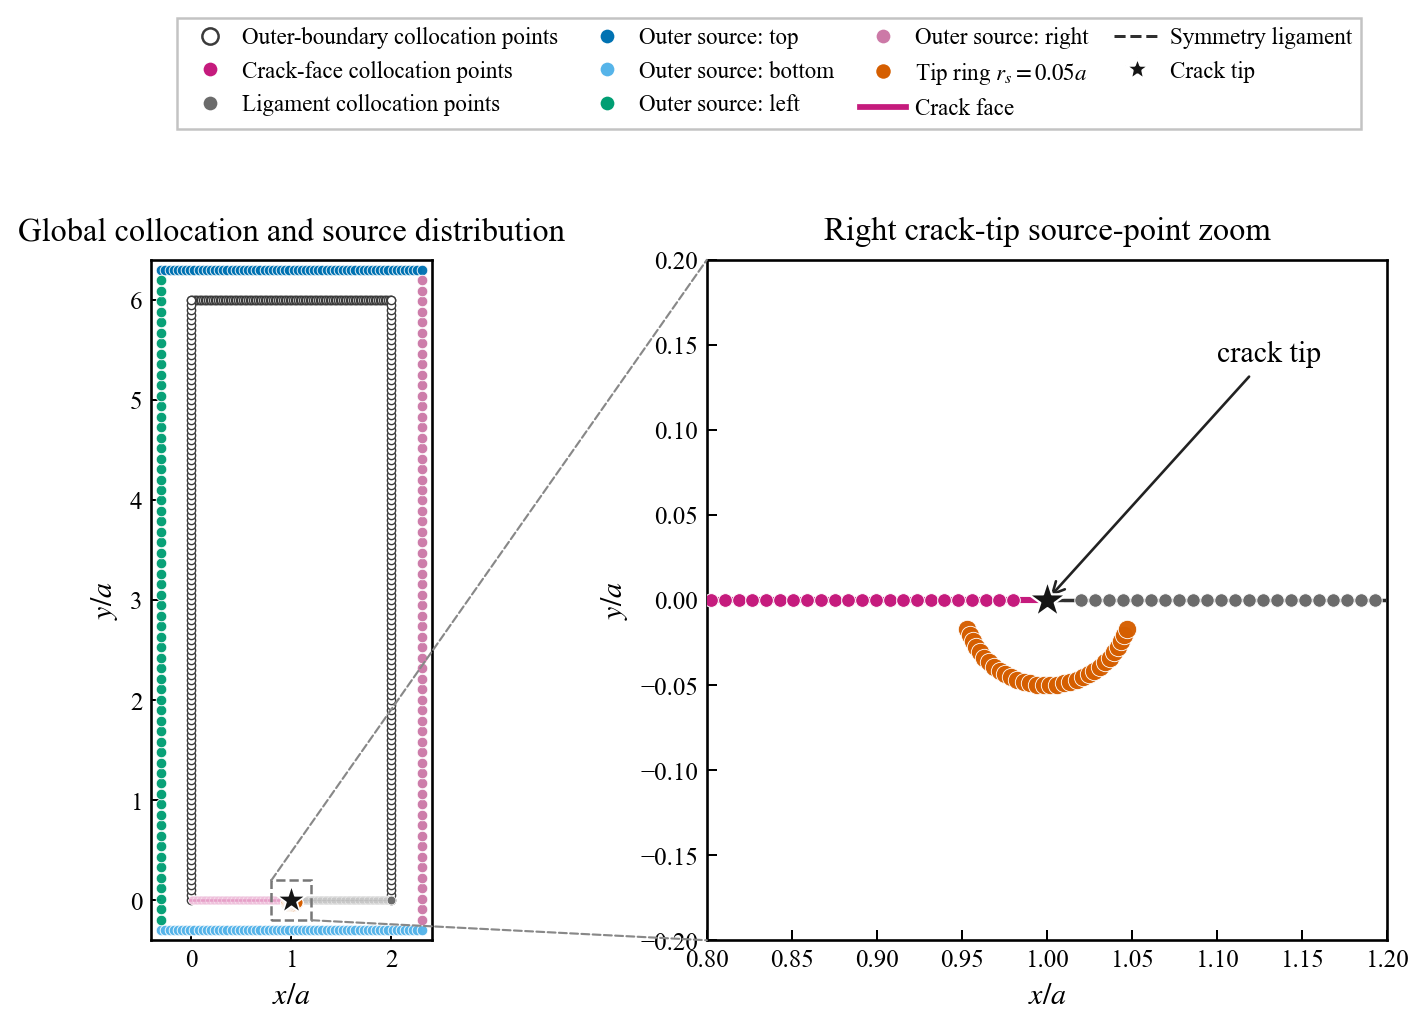

(<Figure size 2196x1080 with 2 Axes>,
 (<Axes: title={'center': 'Global collocation and source distribution'}, xlabel='$x/a$', ylabel='$y/a$'>,
  <Axes: title={'center': 'Right crack-tip source-point zoom'}, xlabel='$x/a$', ylabel='$y/a$'>))

In [143]:
def generate_source_points() -> torch.Tensor:
    mx = cfg["src_margin_x_factor"] * b
    my = cfg["src_margin_y_factor"] * h
    n = cfg["n_src_side"]

    xs = torch.linspace(-mx, b + mx, n, device=device)
    ys = torch.linspace(-my, h + my, n, device=device)

    src = []

    # Rectangle surrounding [0,b] x [0,h].
    for x in xs:
        src.append(torch.stack([x, torch.tensor(-my, device=device)]))
        src.append(torch.stack([x, torch.tensor(h + my, device=device)]))

    # Avoid repeating the four rectangle corners.
    for y in ys[1:-1]:
        src.append(torch.stack([torch.tensor(-mx, device=device), y]))
        src.append(torch.stack([torch.tensor(b + mx, device=device), y]))

    # Local source ring(s) below the crack tip.
    count = cfg["tip_cluster_count"]
    if count > 0:
        angles = torch.linspace(
            math.radians(cfg["tip_cluster_angle_min_deg"]),
            math.radians(cfg["tip_cluster_angle_max_deg"]),
            count,
            device=device,
        )

        for radius_factor in cfg["tip_cluster_radii"]:
            radius = radius_factor * a
            for theta in angles:
                sx = a + radius * torch.cos(theta)
                sy = radius * torch.sin(theta)
                if sy < -1.0e-8:
                    src.append(torch.stack([sx, sy]))

    return torch.stack(src, dim=0)


src_pts = generate_source_points()
outer_source_count = 4 * cfg["n_src_side"] - 4
local_source_count = src_pts.shape[0] - outer_source_count

print("outer sources =", outer_source_count)
print("local sources =", local_source_count)
print("total sources =", src_pts.shape[0])
print("trainable parameters expected =", 2 * src_pts.shape[0] + 1)

# ==========================================
# 论文版源点与边界配点可视化（包含裂尖局部放大）
# ==========================================

from matplotlib.patches import ConnectionPatch, Rectangle
from matplotlib.lines import Line2D


def _to_numpy_points(points):
    """将 torch.Tensor 或 numpy 数组统一为 N x 2 的 NumPy 数组。"""
    if torch.is_tensor(points):
        points = points.detach().cpu().numpy()
    points = np.asarray(points, dtype=float)
    return points.reshape(-1, 2)


def _split_quarter_sources(points):
    """按 generate_source_points 的实际生成顺序划分外部和裂尖源点。"""
    points = _to_numpy_points(points)
    n_side = int(cfg["n_src_side"])
    n_outer = 4 * n_side - 4
    pair_end = 2 * n_side

    if points.shape[0] < n_outer:
        raise ValueError(
            f"源点数量为 {points.shape[0]}，小于预期的外部源点数量 {n_outer}。"
        )

    outer = points[:n_outer]
    return {
        "bottom": outer[0:pair_end:2],
        "top": outer[1:pair_end:2],
        "left": outer[pair_end:n_outer:2],
        "right": outer[pair_end + 1:n_outer:2],
        "tip": points[n_outer:],
    }


def _split_tip_rings(tip_points, radii):
    """按到裂尖 (a,0) 的距离将局部源点划分为不同半径环。"""
    tip_points = _to_numpy_points(tip_points)
    radii = np.asarray(radii, dtype=float)
    if tip_points.size == 0:
        return [np.empty((0, 2), dtype=float) for _ in radii]

    r = np.hypot(tip_points[:, 0] - float(a), tip_points[:, 1])
    ring_index = np.argmin(np.abs(r[:, None] - radii[None, :]), axis=1)
    return [tip_points[ring_index == i] for i in range(radii.size)]


def plot_mode_ii_quarter_source_distribution(
    save_name="mode_ii_quarter_source_distribution_paper.png",
    dpi=600,
):
    """绘制适用于论文的二型中心裂纹四分之一模型配点和源点分布图。"""
    global src_pts
    if "src_pts" not in globals():
        if "generate_source_points" not in globals():
            raise NameError("请先运行源点生成单元，以定义 generate_source_points。")
        src_pts = generate_source_points()

    a0, b0, h0 = float(a), float(b), float(h)
    unit = a0 if abs(a0) > 1.0e-14 else 1.0
    source_groups = _split_quarter_sources(src_pts)
    radii = np.asarray(cfg["tip_cluster_radii"], dtype=float) * a0
    tip_rings = _split_tip_rings(source_groups["tip"], radii)

    plt.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Times New Roman", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "axes.linewidth": 1.05,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.major.size": 4.0,
        "ytick.major.size": 4.0,
    })

    boundary_color = "#3A3A3A"
    crack_color = "#C51B7D"
    ligament_color = "#303030"
    source_colors = {
        "top": "#0072B2",
        "bottom": "#56B4E9",
        "left": "#009E73",
        "right": "#CC79A7",
    }
    ring_colors = ["#D55E00", "#E69F00", "#7A5195", "#44AA99"]

    fig = plt.figure(figsize=(12.2, 6.0), dpi=180)
    grid = fig.add_gridspec(1, 2, width_ratios=[0.82, 1.45], wspace=0.16)
    ax_global = fig.add_subplot(grid[0, 0])
    ax_zoom = fig.add_subplot(grid[0, 1])

    def scatter(ax, points, color, size, label=None, zorder=4):
        points = _to_numpy_points(points)
        if len(points) == 0:
            return
        ax.scatter(
            points[:, 0] / unit,
            points[:, 1] / unit,
            s=size,
            c=color,
            edgecolors="white",
            linewidths=0.35,
            alpha=0.97,
            label=label,
            zorder=zorder,
        )

    # 域轮廓、裂纹面和对称韧带。
    for ax in (ax_global, ax_zoom):
        ax.plot(
            np.array([0.0, b0, b0, 0.0, 0.0]) / unit,
            np.array([0.0, 0.0, h0, h0, 0.0]) / unit,
            color="#303030",
            lw=1.35,
            zorder=1,
        )
        ax.plot(
            np.array([0.0, a0]) / unit,
            [0.0, 0.0],
            color=crack_color,
            lw=2.45,
            solid_capstyle="round",
            zorder=3,
        )
        ax.plot(
            np.array([a0, b0]) / unit,
            [0.0, 0.0],
            color=ligament_color,
            lw=1.25,
            ls="--",
            zorder=3,
        )

    # 外边界、裂纹面和韧带的配点采用不同但克制的视觉编码。
    outer_bnd = np.vstack([
        _to_numpy_points(bnd_pts["top"]),
        _to_numpy_points(bnd_pts["right"]),
        _to_numpy_points(bnd_pts["left"]),
    ])
    crack_bnd = _to_numpy_points(bnd_pts["crack"])
    ligament_bnd = _to_numpy_points(bnd_pts["ligament"])

    ax_global.scatter(
        outer_bnd[:, 0] / unit, outer_bnd[:, 1] / unit,
        s=11, facecolors="white", edgecolors=boundary_color,
        linewidths=0.55, zorder=3,
    )
    ax_global.scatter(
        crack_bnd[:, 0] / unit, crack_bnd[:, 1] / unit,
        s=13, c=crack_color, edgecolors="white", linewidths=0.28, zorder=4,
    )
    ax_global.scatter(
        ligament_bnd[:, 0] / unit, ligament_bnd[:, 1] / unit,
        s=12, c="#6B6B6B", edgecolors="white", linewidths=0.25, zorder=4,
    )

    # 四条外部源点边以不同颜色显示，便于论文中说明源点位于物理域外。
    for name in ("top", "bottom", "left", "right"):
        scatter(ax_global, source_groups[name], source_colors[name], size=18)

    # 裂尖局部环源点。
    for ring_id, ring in enumerate(tip_rings):
        scatter(
            ax_global,
            ring,
            ring_colors[ring_id % len(ring_colors)],
            size=27,
        )

    ax_global.scatter(
        [a0 / unit], [0.0],
        marker="*", s=150, c="#151515", edgecolors="white",
        linewidths=0.7, zorder=8,
    )
    ax_global.set_title("Global collocation and source distribution", fontsize=13, pad=8)
    ax_global.set_xlabel(r"$x/a$", fontsize=12)
    ax_global.set_ylabel(r"$y/a$", fontsize=12)
    ax_global.set_aspect("equal", adjustable="box")

    mx = float(cfg["src_margin_x_factor"]) * b0
    my = float(cfg["src_margin_y_factor"]) * h0
    ax_global.set_xlim((-mx - 0.10 * a0) / unit, (b0 + mx + 0.10 * a0) / unit)
    ax_global.set_ylim((-my - 0.10 * a0) / unit, (h0 + my + 0.10 * a0) / unit)
    ax_global.grid(False)

    # 裂尖放大区域只显示相邻的裂纹面、韧带配点和局部环源点。
    largest_radius = float(np.max(radii)) if len(radii) else 0.16 * a0
    half_width = max(1.65 * largest_radius, 0.20 * a0)
    x0, x1 = a0 - half_width, a0 + half_width
    y0, y1 = -half_width, half_width

    local_crack = crack_bnd[
        (crack_bnd[:, 0] >= x0) & (crack_bnd[:, 0] <= x1)
    ]
    local_ligament = ligament_bnd[
        (ligament_bnd[:, 0] >= x0) & (ligament_bnd[:, 0] <= x1)
    ]
    if len(local_crack):
        ax_zoom.scatter(
            local_crack[:, 0] / unit, local_crack[:, 1] / unit,
            s=30, c=crack_color, edgecolors="white", linewidths=0.38, zorder=4,
        )
    if len(local_ligament):
        ax_zoom.scatter(
            local_ligament[:, 0] / unit, local_ligament[:, 1] / unit,
            s=29, c="#6B6B6B", edgecolors="white", linewidths=0.36, zorder=4,
        )
    for ring_id, ring in enumerate(tip_rings):
        scatter(
            ax_zoom,
            ring,
            ring_colors[ring_id % len(ring_colors)],
            size=54,
        )
    ax_zoom.scatter(
        [a0 / unit], [0.0],
        marker="*", s=255, c="#151515", edgecolors="white",
        linewidths=0.9, zorder=8,
    )
    ax_zoom.annotate(
        "crack tip",
        xy=(a0 / unit, 0.0),
        xytext=((a0 + 0.50 * half_width) / unit, 0.70 * half_width / unit),
        fontsize=12,
        arrowprops=dict(arrowstyle="->", lw=1.05, color="#222222"),
    )
    ax_zoom.set_title("Right crack-tip source-point zoom", fontsize=13, pad=8)
    ax_zoom.set_xlabel(r"$x/a$", fontsize=12)
    ax_zoom.set_ylabel(r"$y/a$", fontsize=12)
    ax_zoom.set_aspect("equal", adjustable="box")
    ax_zoom.set_xlim(x0 / unit, x1 / unit)
    ax_zoom.set_ylim(y0 / unit, y1 / unit)
    ax_zoom.grid(False)

    # 左图中的虚线框和连接线说明右图的放大来源。
    rectangle = Rectangle(
        (x0 / unit, y0 / unit),
        (x1 - x0) / unit,
        (y1 - y0) / unit,
        fill=False,
        ec="#777777",
        ls="--",
        lw=1.0,
        zorder=8,
    )
    ax_global.add_patch(rectangle)
    for p_global, p_zoom in (
        ((x0 / unit, y1 / unit), (x0 / unit, y1 / unit)),
        ((x1 / unit, y0 / unit), (x0 / unit, y0 / unit)),
    ):
        fig.add_artist(ConnectionPatch(
            xyA=p_global,
            coordsA=ax_global.transData,
            xyB=p_zoom,
            coordsB=ax_zoom.transData,
            color="#888888",
            ls="--",
            lw=0.85,
        ))

    legend_handles = [
        Line2D([0], [0], marker="o", color="none", markerfacecolor="white",
               markeredgecolor=boundary_color, markersize=6.5,
               label="Outer-boundary collocation points"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor=crack_color,
               markeredgecolor="white", markersize=6.5,
               label="Crack-face collocation points"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor="#6B6B6B",
               markeredgecolor="white", markersize=6.5,
               label="Ligament collocation points"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor=source_colors["top"],
               markeredgecolor="white", markersize=6.5, label="Outer source: top"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor=source_colors["bottom"],
               markeredgecolor="white", markersize=6.5, label="Outer source: bottom"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor=source_colors["left"],
               markeredgecolor="white", markersize=6.5, label="Outer source: left"),
        Line2D([0], [0], marker="o", color="none", markerfacecolor=source_colors["right"],
               markeredgecolor="white", markersize=6.5, label="Outer source: right"),
    ]
    for ring_id, radius in enumerate(radii):
        legend_handles.append(Line2D(
            [0], [0], marker="o", color="none",
            markerfacecolor=ring_colors[ring_id % len(ring_colors)],
            markeredgecolor="white", markersize=6.8,
            label=rf"Tip ring $r_s={radius / unit:.2f}a$",
        ))
    legend_handles.extend([
        Line2D([0], [0], color=crack_color, lw=2.3, label="Crack face"),
        Line2D([0], [0], color=ligament_color, lw=1.2, ls="--",
               label="Symmetry ligament"),
        Line2D([0], [0], marker="*", color="none", markerfacecolor="#151515",
               markeredgecolor="white", markersize=10, label="Crack tip"),
    ])
    
    fig.subplots_adjust(top=0.76, bottom=0.13, left=0.065, right=0.985)

    # 右图向左平移；数值是相对整张 figure 宽度的比例
    zoom_pos = ax_zoom.get_position()
    shift_left = 0.15

    ax_zoom.set_position([
        zoom_pos.x0 - shift_left,
        zoom_pos.y0,
        zoom_pos.width,
        zoom_pos.height,
    ])
    # 按左右两张图的整体范围计算图例中心
    global_pos = ax_global.get_position()
    zoom_pos = ax_zoom.get_position()
    legend_center_x = (global_pos.x0 + zoom_pos.x1) / 2

    fig.legend(
        handles=legend_handles,
        loc="upper center",
        bbox_to_anchor=(legend_center_x, 0.995),
        bbox_transform=fig.transFigure,
        ncol=4,
        frameon=True,
        fancybox=False,
        edgecolor="#B5B5B5",
        facecolor="white",
        fontsize=9.2,
        columnspacing=1.10,
        handletextpad=0.42,
    )
    fig.savefig(save_name, dpi=dpi, bbox_inches="tight", pad_inches=0.08)
    plt.show()
    return fig, (ax_global, ax_zoom)



# 源点、边界配点生成完成后，运行本行即可输出论文版图像。
plot_mode_ii_quarter_source_distribution()


## 4. Kolosov–Muskhelishvili 公式与点力基本解

保持原 Mode-II notebook 中的 K-M 约定和 Kelvin 点力复势实现不变。

In [131]:
def km_response(
    z: torch.Tensor,
    phi: torch.Tensor,
    dphi: torch.Tensor,
    ddphi: torch.Tensor,
    psi: torch.Tensor,
    dpsi: torch.Tensor,
):
    stress_sum = 4.0 * torch.real(dphi)
    stress_diff_complex = 2.0 * (torch.conj(z) * ddphi + dpsi)
    stress_diff = torch.real(stress_diff_complex)

    sigma_xy = 0.5 * torch.imag(stress_diff_complex)
    sigma_xx = 0.5 * (stress_sum - stress_diff)
    sigma_yy = 0.5 * (stress_sum + stress_diff)

    displacement_complex = (
        kappa * phi - z * torch.conj(dphi) - torch.conj(psi)
    ) / (2.0 * mu)

    ux = torch.real(displacement_complex)
    uy = torch.imag(displacement_complex)

    return ux, uy, sigma_xx, sigma_yy, sigma_xy


def complex_point_force_potential_response(
    x: torch.Tensor,
    y: torch.Tensor,
    sx: torch.Tensor,
    sy: torch.Tensor,
    fx: float,
    fy: float,
    add_kelvin_constant: bool = True,
):
    z = torch.complex(x.reshape(-1), y.reshape(-1))
    zeta = torch.complex(sx.reshape(()), sy.reshape(()))
    p_force = torch.as_tensor(complex(fx, fy), dtype=z.dtype, device=device)
    q = z - zeta

    den = 2.0 * math.pi * (kappa + 1.0)
    logq = torch.log(q)

    phi = -p_force / den * logq
    dphi = -p_force / den / q
    ddphi = p_force / den / (q * q)

    psi = (
        kappa * torch.conj(p_force) / den * logq
        + p_force * torch.conj(zeta) / den / q
    )
    dpsi = (
        kappa * torch.conj(p_force) / den / q
        - p_force * torch.conj(zeta) / den / (q * q)
    )

    if add_kelvin_constant:
        phi = phi + p_force / (2.0 * math.pi * kappa * (kappa + 1.0))

    return km_response(z, phi, dphi, ddphi, psi, dpsi)

## 5. Mode-II 裂尖富集与核矩阵

最后一个系数就是 $K_{II}$。每个 MFS 源点对应两个独立单位点力方向，因此普通核参数数目为 $2N_s$。

In [132]:
def mode_ii_tip_response(x: torch.Tensor, y: torch.Tensor):
    """Unit-KII right-tip asymptotic field at (a,0)."""
    xl = x.reshape(-1) - a
    yl = y.reshape(-1)

    r = torch.sqrt(torch.clamp(xl * xl + yl * yl, min=1.0e-30))
    theta = torch.atan2(yl, xl)

    c2 = torch.cos(0.5 * theta)
    s2 = torch.sin(0.5 * theta)
    c32 = torch.cos(1.5 * theta)
    s32 = torch.sin(1.5 * theta)
    ct = torch.cos(theta)

    root = torch.sqrt(r / (2.0 * math.pi))
    inv_root = 1.0 / torch.sqrt(2.0 * math.pi * r)

    ux = root * s2 * (kappa + 2.0 + ct) / (2.0 * mu)
    uy = -root * c2 * (kappa - 2.0 + ct) / (2.0 * mu)

    sigma_xx = -inv_root * s2 * (2.0 + c2 * c32)
    sigma_yy =  inv_root * s2 * c2 * c32
    sigma_xy =  inv_root * c2 * (1.0 - s2 * s32)

    return ux, uy, sigma_xx, sigma_yy, sigma_xy


Q_NAMES = ("ux", "uy", "sxx", "syy", "sxy")


def build_kernel_columns(points: torch.Tensor, sources: torch.Tensor):
    x = points[:, 0:1]
    y = points[:, 1:2]
    cols = {q: [] for q in Q_NAMES}

    def add_response(resp):
        for q, value in zip(Q_NAMES, resp):
            cols[q].append(value.reshape(-1))

    for source in sources:
        add_response(complex_point_force_potential_response(
            x, y, source[0], source[1], 1.0, 0.0
        ))
        add_response(complex_point_force_potential_response(
            x, y, source[0], source[1], 0.0, 1.0
        ))

    return {q: torch.stack(values, dim=1) for q, values in cols.items()}


def build_tip_columns(points: torch.Tensor):
    resp = mode_ii_tip_response(points[:, 0:1], points[:, 1:2])
    return {q: value.reshape(-1) for q, value in zip(Q_NAMES, resp)}

## 6. 单域核矩阵、列归一化与可辨识性诊断

残差矩阵和训练 loss 使用同一组物理边界条件。列归一化只改善数值尺度，不改变真实物理系数。

In [133]:
BASIS_KEYS = ("top", "right", "left", "crack", "ligament")

basis = {k: build_kernel_columns(bnd_pts[k], src_pts) for k in BASIS_KEYS}
tip_basis = {k: build_tip_columns(bnd_pts[k]) for k in BASIS_KEYS}

n_kernel = 2 * src_pts.shape[0]
n_total_params = n_kernel + 1

print("kernel coefficients =", n_kernel)
print("K_II coefficient    = 1")
print("total trainable parameters =", n_total_params)


def physical_row(key: str, quantity: str, include_tip: bool = True):
    n = bnd_pts[key].shape[0]
    A = torch.zeros((n, n_total_params), device=device)
    A[:, :n_kernel] = basis[key][quantity]
    if include_tip:
        A[:, -1] = tip_basis[key][quantity]
    return A


A_rows = []
b_rows = []
row_names = []


def add_linear_block(A, target, weight, name):
    # weight * mean(residual^2) == ||sqrt(weight/n)*(A c-b)||_2^2
    n = A.shape[0]
    fac = math.sqrt(weight / n)
    A_rows.append(fac * A)

    if torch.is_tensor(target):
        t = target.reshape(-1, 1).to(device=device, dtype=A.dtype)
    else:
        t = torch.full((n, 1), float(target), device=device, dtype=A.dtype)

    b_rows.append(fac * t)
    row_names.append((name, n))


# Top: sigma_xy=tau0, sigma_yy=0
add_linear_block(physical_row("top", "sxy"), tau0, cfg["w_top"], "top_sxy")
add_linear_block(physical_row("top", "syy"), 0.0, cfg["w_top"], "top_syy")

# Right: sigma_xx=0, sigma_xy=tau0
add_linear_block(physical_row("right", "sxx"), 0.0, cfg["w_right"], "right_sxx")
add_linear_block(physical_row("right", "sxy"), tau0, cfg["w_right"], "right_sxy")

# Left antisymmetry about x=0: uy=0, sigma_xx=0
add_linear_block(physical_row("left", "uy"), 0.0, cfg["w_left"], "left_uy")
add_linear_block(physical_row("left", "sxx"), 0.0, cfg["w_left"], "left_sxx")

# Crack face: traction free
add_linear_block(physical_row("crack", "syy"), 0.0, cfg["w_crack"], "crack_syy")
add_linear_block(physical_row("crack", "sxy"), 0.0, cfg["w_crack"], "crack_sxy")

# Ligament antisymmetry about y=0: ux=0, sigma_yy=0.
# IMPORTANT: sigma_xy is NOT constrained to zero here.
add_linear_block(physical_row("ligament", "ux"), 0.0, cfg["w_ligament"], "ligament_ux")
add_linear_block(physical_row("ligament", "syy"), 0.0, cfg["w_ligament"], "ligament_syy")

A_phys = torch.cat(A_rows, dim=0)
b_phys = torch.cat(b_rows, dim=0)

col_scale = torch.linalg.norm(A_phys, dim=0).detach()
col_scale = torch.where(col_scale > 0.0, col_scale, torch.ones_like(col_scale))
A_norm = A_phys / col_scale.reshape(1, -1)

print("A shape =", tuple(A_norm.shape))
print("column scale range =", col_scale.min().item(), col_scale.max().item())

# SVD diagnostic on CPU for portability.
with torch.no_grad():
    sv = torch.linalg.svdvals(A_norm.detach().cpu())
    threshold = cfg["svd_rtol"] * sv.max()
    numerical_rank = int(torch.sum(sv > threshold).item())
    nullity = n_total_params - numerical_rank
    kept = sv[sv > threshold]
    cond_est = (kept.max() / kept.min()).item() if kept.numel() else float("inf")

print("\n=== Linear-system identifiability diagnostic ===")
print("numerical rank :", numerical_rank)
print("nullity        :", nullity)
print("cond. estimate :", f"{cond_est:.6e}")

kernel coefficients = 568
K_II coefficient    = 1
total trainable parameters = 569
A shape = (1206, 569)
column scale range = 0.343496815124994 6.877604791220747

=== Linear-system identifiability diagnostic ===
numerical rank : 491
nullity        : 78
cond. estimate : 9.869824e+09


## 7. 四分之一域单层 PIKFNN

参数向量为

$$
[\mathbf c,\ K_{II}],
$$

其中 $\mathbf c$ 是全部点力核线性系数，最后一个物理系数为 $K_{II}$。

In [134]:
class QuarterModeIIPIKFNN(nn.Module):
    def __init__(self):
        super().__init__()
        self.theta = nn.Parameter(torch.zeros(n_total_params, device=device))

        # Only an initial guess, not a supervised target.
        kii_scale_guess = tau0 * math.sqrt(math.pi * a)
        with torch.no_grad():
            self.theta[-1] = kii_scale_guess * col_scale[-1]

    def physical_coeffs(self):
        c = self.theta / col_scale
        kernel = c[:n_kernel]
        kii = c[-1]
        return kernel, kii

    def quantity(self, key: str, q: str, include_tip: bool = True):
        kernel, kii = self.physical_coeffs()
        value = basis[key][q] @ kernel
        if include_tip:
            value = value + tip_basis[key][q] * kii
        return value

    def kernel_regularization(self):
        kernel, _ = self.physical_coeffs()
        return torch.mean(kernel * kernel)


model = QuarterModeIIPIKFNN().to(device)
print("initial K_II =", model.physical_coeffs()[1].detach().item())

initial K_II = 1.7724538509055157


## 8. Mode-II 四分之一边界损失

特别注意韧带条件是 $u_x=0,\ \sigma_{yy}=0$，而不是 $\sigma_{xy}=0$。

In [135]:
def mse(x):
    return torch.mean(x * x)


def loss_components(net: QuarterModeIIPIKFNN):
    L = {}

    L["top"] = cfg["w_top"] * (
        mse(net.quantity("top", "sxy") - tau0)
        + mse(net.quantity("top", "syy"))
    )

    L["right"] = cfg["w_right"] * (
        mse(net.quantity("right", "sxx"))
        + mse(net.quantity("right", "sxy") - tau0)
    )

    L["left"] = cfg["w_left"] * (
        mse(net.quantity("left", "uy"))
        + mse(net.quantity("left", "sxx"))
    )

    L["crack"] = cfg["w_crack"] * (
        mse(net.quantity("crack", "syy"))
        + mse(net.quantity("crack", "sxy"))
    )

    L["ligament"] = cfg["w_ligament"] * (
        mse(net.quantity("ligament", "ux"))
        + mse(net.quantity("ligament", "syy"))
    )

    L["reg"] = cfg["lambda_reg"] * net.kernel_regularization()
    total = sum(L.values())
    return total, L


def print_loss_components(net, prefix=""):
    total, L = loss_components(net)
    kii = net.physical_coeffs()[1].detach().item()

    print(prefix + f"total = {total.detach().item():.8e}    KII = {kii:.10f}")
    for key in ("top", "right", "left", "crack", "ligament", "reg"):
        print(f"  {key:10s}: {L[key].detach().item():.8e}")
    return total, L


print_loss_components(model, prefix="Initial ")

Initial total = 4.56467908e+00    KII = 1.7724538509
  top       : 2.03675651e+00
  right     : 1.19754497e+00
  left      : 1.33037760e+00
  crack     : 7.64644531e-13
  ligament  : 0.00000000e+00
  reg       : 0.00000000e+00


(tensor(4.5647, device='cuda:0', grad_fn=<AddBackward0>),
 {'top': tensor(2.0368, device='cuda:0', grad_fn=<MulBackward0>),
  'right': tensor(1.1975, device='cuda:0', grad_fn=<MulBackward0>),
  'left': tensor(1.3304, device='cuda:0', grad_fn=<MulBackward0>),
  'crack': tensor(7.6464e-13, device='cuda:0', grad_fn=<MulBackward0>),
  'ligament': tensor(0., device='cuda:0', grad_fn=<MulBackward0>),
  'reg': tensor(0., device='cuda:0', grad_fn=<MulBackward0>)})

## 9. Adam + L-BFGS 训练

如果希望与当前 Mode-I 单圆弧 notebook 做严格优化器对比，可把 `adam_steps` 改为 0；默认先保留原 Mode-II 代码的 Adam 热启动。

In [136]:
LOSS_HISTORY_KEYS = ("top", "right", "left", "crack", "ligament", "reg")

history = {
    "step": [],
    "phase": [],
    "total": [],
    "KII": [],
    **{key: [] for key in LOSS_HISTORY_KEYS},
}


def record(step, phase):
    """记录总损失、各物理边界分项损失及当前 K_II。"""
    total, components = loss_components(model)
    kii = model.physical_coeffs()[1].detach().item()

    history["step"].append(int(step))
    history["phase"].append(phase)
    history["total"].append(total.detach().item())
    history["KII"].append(kii)
    for key in LOSS_HISTORY_KEYS:
        history[key].append(components[key].detach().item())

    return total, kii


def train_model():
    global_step = 0
    t0 = time.time()
    record(global_step, "Initial")

    if cfg["adam_steps"] > 0:
        opt_adam = torch.optim.Adam(model.parameters(), lr=cfg["adam_lr"])

        for it in range(1, cfg["adam_steps"] + 1):
            opt_adam.zero_grad(set_to_none=True)
            total, _ = loss_components(model)
            total.backward()
            opt_adam.step()
            global_step += 1

            if it == 1 or it % cfg["adam_print_every"] == 0:
                record(global_step, "Adam")
                print("\n" + "=" * 78)
                print(f"Adam {it:5d}/{cfg['adam_steps']}")
                print_loss_components(model)

    opt_lbfgs = torch.optim.LBFGS(
        model.parameters(),
        lr=1.0,
        max_iter=cfg["lbfgs_max_iter"],
        max_eval=cfg["lbfgs_max_iter"] * 2,
        tolerance_grad=1.0e-12,
        tolerance_change=1.0e-14,
        history_size=100,
        line_search_fn="strong_wolfe",
    )

    for epoch in range(1, cfg["lbfgs_epochs"] + 1):
        def closure():
            opt_lbfgs.zero_grad(set_to_none=True)
            total, _ = loss_components(model)
            total.backward()
            return total

        opt_lbfgs.step(closure)
        global_step += 1

        if epoch == 1 or epoch % cfg["lbfgs_print_every"] == 0:
            record(global_step, "L-BFGS")
            print("\n" + "=" * 78)
            print(f"LBFGS {epoch:4d}/{cfg['lbfgs_epochs']}")
            print_loss_components(model)

    elapsed = time.time() - t0
    print("\n" + "=" * 78)
    print(f"Training time: {elapsed:.2f} s")
    return elapsed


elapsed = train_model()



Adam     1/1500
total = 3.11952580e+00    KII = 1.7590210553
  top       : 1.17151523e+00
  right     : 8.98358741e-01
  left      : 6.09275482e-01
  crack     : 1.37328354e-01
  ligament  : 3.03047999e-01
  reg       : 2.30244609e-14

Adam   100/1500
total = 8.08127313e-03    KII = 1.8552356084
  top       : 9.29158817e-05
  right     : 4.96999523e-03
  left      : 1.47168514e-03
  crack     : 1.25643893e-03
  ligament  : 2.90237936e-04
  reg       : 5.53723226e-13

Adam   200/1500
total = 1.88502241e-03    KII = 2.0032244636
  top       : 2.57177555e-05
  right     : 1.05229047e-03
  left      : 3.49824431e-04
  crack     : 3.71811015e-04
  ligament  : 8.53787355e-05
  reg       : 5.81950374e-13

Adam   300/1500
total = 6.62417394e-04    KII = 2.0839987304
  top       : 1.57200210e-05
  right     : 3.12658932e-04
  left      : 1.17108194e-04
  crack     : 1.71336763e-04
  ligament  : 4.55934834e-05
  reg       : 6.01644667e-13

Adam   400/1500
total = 3.09082442e-04    KII = 2.12848

## 10. 损失函数收敛曲线

绘制总损失以及五类物理边界条件对应的加权损失分项。横坐标中的竖虚线表示优化器由 Adam 切换至 L-BFGS 的位置。

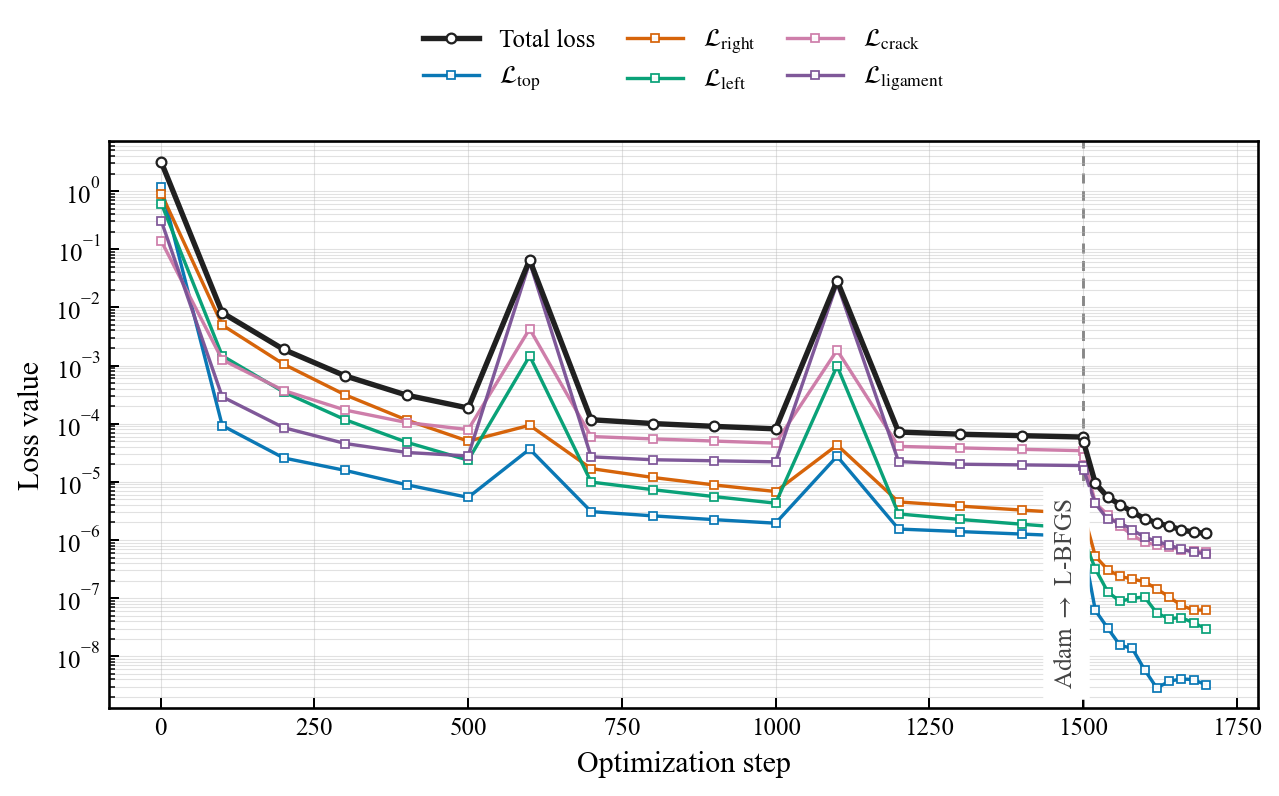

In [137]:
def plot_mode_ii_quarter_loss_history(
    save_name="mode_ii_quarter_loss_history.png",
    dpi=600,
    show_regularization=False,
    drop_initial=True,
):
    """绘制适用于论文的总损失及各边界损失收敛曲线。"""
    if len(history["step"]) == 0:
        raise RuntimeError("训练历史为空。请先运行 Adam + L-BFGS 训练单元。")

    plt.rcParams.update({
        "font.family": "serif",
        "font.serif": ["Times New Roman", "DejaVu Serif"],
        "mathtext.fontset": "stix",
        "axes.linewidth": 1.05,
        "xtick.direction": "in",
        "ytick.direction": "in",
        "xtick.major.size": 4.0,
        "ytick.major.size": 4.0,
    })

    steps_all = np.asarray(history["step"], dtype=float)
    # step=0 仅表示随机初始化状态，个别边界项可能接近机器精度，
    # 在对数坐标中会破坏正文图的可读性，因此默认不参与论文绘图。
    valid = steps_all > 0 if drop_initial else np.ones_like(steps_all, dtype=bool)
    if not np.any(valid):
        valid = np.ones_like(steps_all, dtype=bool)

    steps = steps_all[valid]
    safe = lambda key: np.clip(np.asarray(history[key], dtype=float)[valid], 1.0e-30, None)

    fig, ax = plt.subplots(figsize=(7.6, 5.0), dpi=180)

    total_values = safe("total")
    ax.semilogy(
        steps, total_values,
        color="#202020", lw=2.15, marker="o", ms=3.9,
        mfc="white", mew=0.9, label="Total loss", zorder=6,
    )

    component_style = {
        "top":      (r"$\mathcal{L}_{\mathrm{top}}$", "#0072B2", "-"),
        "right":    (r"$\mathcal{L}_{\mathrm{right}}$", "#D55E00", "-"),
        "left":     (r"$\mathcal{L}_{\mathrm{left}}$", "#009E73", "-"),
        "crack":    (r"$\mathcal{L}_{\mathrm{crack}}$", "#CC79A7", "-"),
        "ligament": (r"$\mathcal{L}_{\mathrm{ligament}}$", "#7A5195", "-"),
        "reg":      (r"$\mathcal{L}_{\mathrm{reg}}$", "#777777", ":"),
    }

    keys = ["top", "right", "left", "crack", "ligament"]
    if show_regularization:
        keys.append("reg")

    for key in keys:
        label, color, linestyle = component_style[key]
        ax.semilogy(
            steps, safe(key),
            color=color, lw=1.35, ls=linestyle, marker="s", ms=3.1,
            mfc="white", mew=0.7, label=label, alpha=0.96,
        )

    if cfg["adam_steps"] > 0 and any(p == "L-BFGS" for p in history["phase"]):
        switch_x = float(cfg["adam_steps"])
        ax.axvline(
            switch_x, color="#666666", lw=1.0, ls=(0, (4, 3)), zorder=1,
        )
        all_values = np.concatenate([total_values] + [safe(key) for key in keys])
        y_min = max(np.min(all_values) * 0.45, 1.0e-12)
        y_max = np.max(all_values) * 2.3
        ax.set_ylim(y_min, y_max)
        ax.text(
            switch_x - 8.0, y_min * 2.2, "Adam $\\rightarrow$ L-BFGS",
            ha="right", va="bottom", fontsize=10, color="#444444",
            rotation=90, backgroundcolor="white", zorder=7,
        )

    ax.set_xlabel("Optimization step", fontsize=12)
    ax.set_ylabel("Loss value", fontsize=12)
    ax.grid(True, which="both", color="#B8B8B8", lw=0.45, alpha=0.42)
    ax.tick_params(axis="both", which="major", labelsize=10)
    ax.tick_params(axis="both", which="minor", length=2.5)

    ax.legend(
        loc="upper center", bbox_to_anchor=(0.5, 1.24),
        ncol=3, frameon=False, fontsize=10,
        columnspacing=1.25, handlelength=2.25,
    )

    fig.subplots_adjust(top=0.77, left=0.13, right=0.97, bottom=0.14)
    fig.savefig(save_name, dpi=dpi, bbox_inches="tight", facecolor="white")
    plt.show()
    return fig, ax


fig_loss, ax_loss = plot_mode_ii_quarter_loss_history()


## 10. 最终 $K_{II}$ 与边界损失

In [138]:
total_final, L_final = print_loss_components(model, prefix="Final ")

KII_pred = model.physical_coeffs()[1].detach().item()
KII_rel_err = abs(KII_pred - KII_REF) / abs(KII_REF)

print("\n=== Mode-II quarter-domain center-crack result ===")
print(f"K_II predicted  : {KII_pred:.10f}")
print(f"K_II reference  : {KII_REF:.10f}")
print(f"relative error  : {KII_rel_err:.6%}")
print(f"trainable params: {n_total_params}")
print(f"sources         : {src_pts.shape[0]}")
print(f"training time   : {elapsed:.2f} s")

Final total = 1.30396217e-06    KII = 2.1353946299
  top       : 3.22399540e-09
  right     : 6.24790000e-08
  left      : 2.97960496e-08
  crack     : 6.28743887e-07
  ligament  : 5.79718346e-07
  reg       : 8.88174713e-13

=== Mode-II quarter-domain center-crack result ===
K_II predicted  : 2.1353946299
K_II reference  : 2.1025451937
relative error  : 1.562365%
trainable params: 569
sources         : 284
training time   : 86.19 s


In [139]:
# ============================================================
# 全场恢复：由右上 1/4 域预测结果恢复完整 Mode-II 裂纹板
# ============================================================

def evaluate_full_mode_ii_field(nx=None, ny=None, batch_size=2048):
    """
    在完整域 [-b,b] x [-h,h] 上评估应力和位移。
    先映射到右上 1/4 域计算，再按 Mode-II 对称性恢复全场。
    """
    nx = int(cfg["nx_plot"] if nx is None else nx)
    ny = int(cfg["ny_plot"] if ny is None else ny)

    x_plot = np.linspace(-b, b, nx)
    y_plot = np.linspace(-h, h, ny)
    X, Y = np.meshgrid(x_plot, y_plot)

    # 映射到已训练的右上四分之一域
    quarter_points = np.column_stack([
        np.abs(X).reshape(-1),
        np.abs(Y).reshape(-1),
    ])

    q_names = ("ux", "uy", "sxx", "syy", "sxy")
    values = {key: [] for key in q_names}

    with torch.no_grad():
        kernel, kii = model.physical_coeffs()
        kernel = kernel.detach()
        kii = kii.detach()

        for start in range(0, len(quarter_points), batch_size):
            point_batch = quarter_points[start:start + batch_size]

            pts = torch.as_tensor(
                point_batch,
                dtype=torch.get_default_dtype(),
                device=device,
            )

            kernel_basis = build_kernel_columns(pts, src_pts)
            tip_basis_grid = build_tip_columns(pts)

            for key in q_names:
                value = kernel_basis[key] @ kernel + tip_basis_grid[key] * kii
                values[key].append(value.detach().cpu().numpy())

    values = {
        key: np.concatenate(values[key]).reshape(ny, nx)
        for key in q_names
    }

    # Mode-II 对称性恢复
    sign_x = np.where(X < 0.0, -1.0, 1.0)
    sign_y = np.where(Y < 0.0, -1.0, 1.0)

    # 关于 y=0：ux, sxx, syy 为奇；uy, sxy 为偶
    # 关于 x=0：uy, sxx, syy 为奇；ux, sxy 为偶
    ux_full = values["ux"] * sign_y
    uy_full = values["uy"] * sign_x

    sxx_full = values["sxx"] * sign_x * sign_y
    syy_full = values["syy"] * sign_x * sign_y
    sxy_full = values["sxy"]

    von_mises = np.sqrt(
        sxx_full**2
        - sxx_full * syy_full
        + syy_full**2
        + 3.0 * sxy_full**2
    )

    return X, Y, ux_full, uy_full, sxx_full, syy_full, sxy_full, von_mises


# 生成完整域场变量，供后续统计和云图直接调用
X, Y, ux_full, uy_full, sxx_full, syy_full, sxy_full, von_mises = (
    evaluate_full_mode_ii_field()
)

print("Full-field reconstruction completed.")
print("Grid shape:", X.shape)
print("sigma_xy range:", np.nanmin(sxy_full), "to", np.nanmax(sxy_full))

Full-field reconstruction completed.
Grid shape: (361, 181)
sigma_xy range: -0.0003275535067865455 to 26939418.238548115


## 11. 场变量评估与利用对称性恢复全场

对于 Mode II：

关于 $y=0$：$u_x,\sigma_{xx},\sigma_{yy}$ 为奇函数，$u_y,\sigma_{xy}$ 为偶函数。

关于 $x=0$：$u_y,\sigma_{xx},\sigma_{yy}$ 为奇函数，$u_x,\sigma_{xy}$ 为偶函数。

因此可由右上四分之一场恢复完整 $[-b,b]\times[-h,h]$ 场。

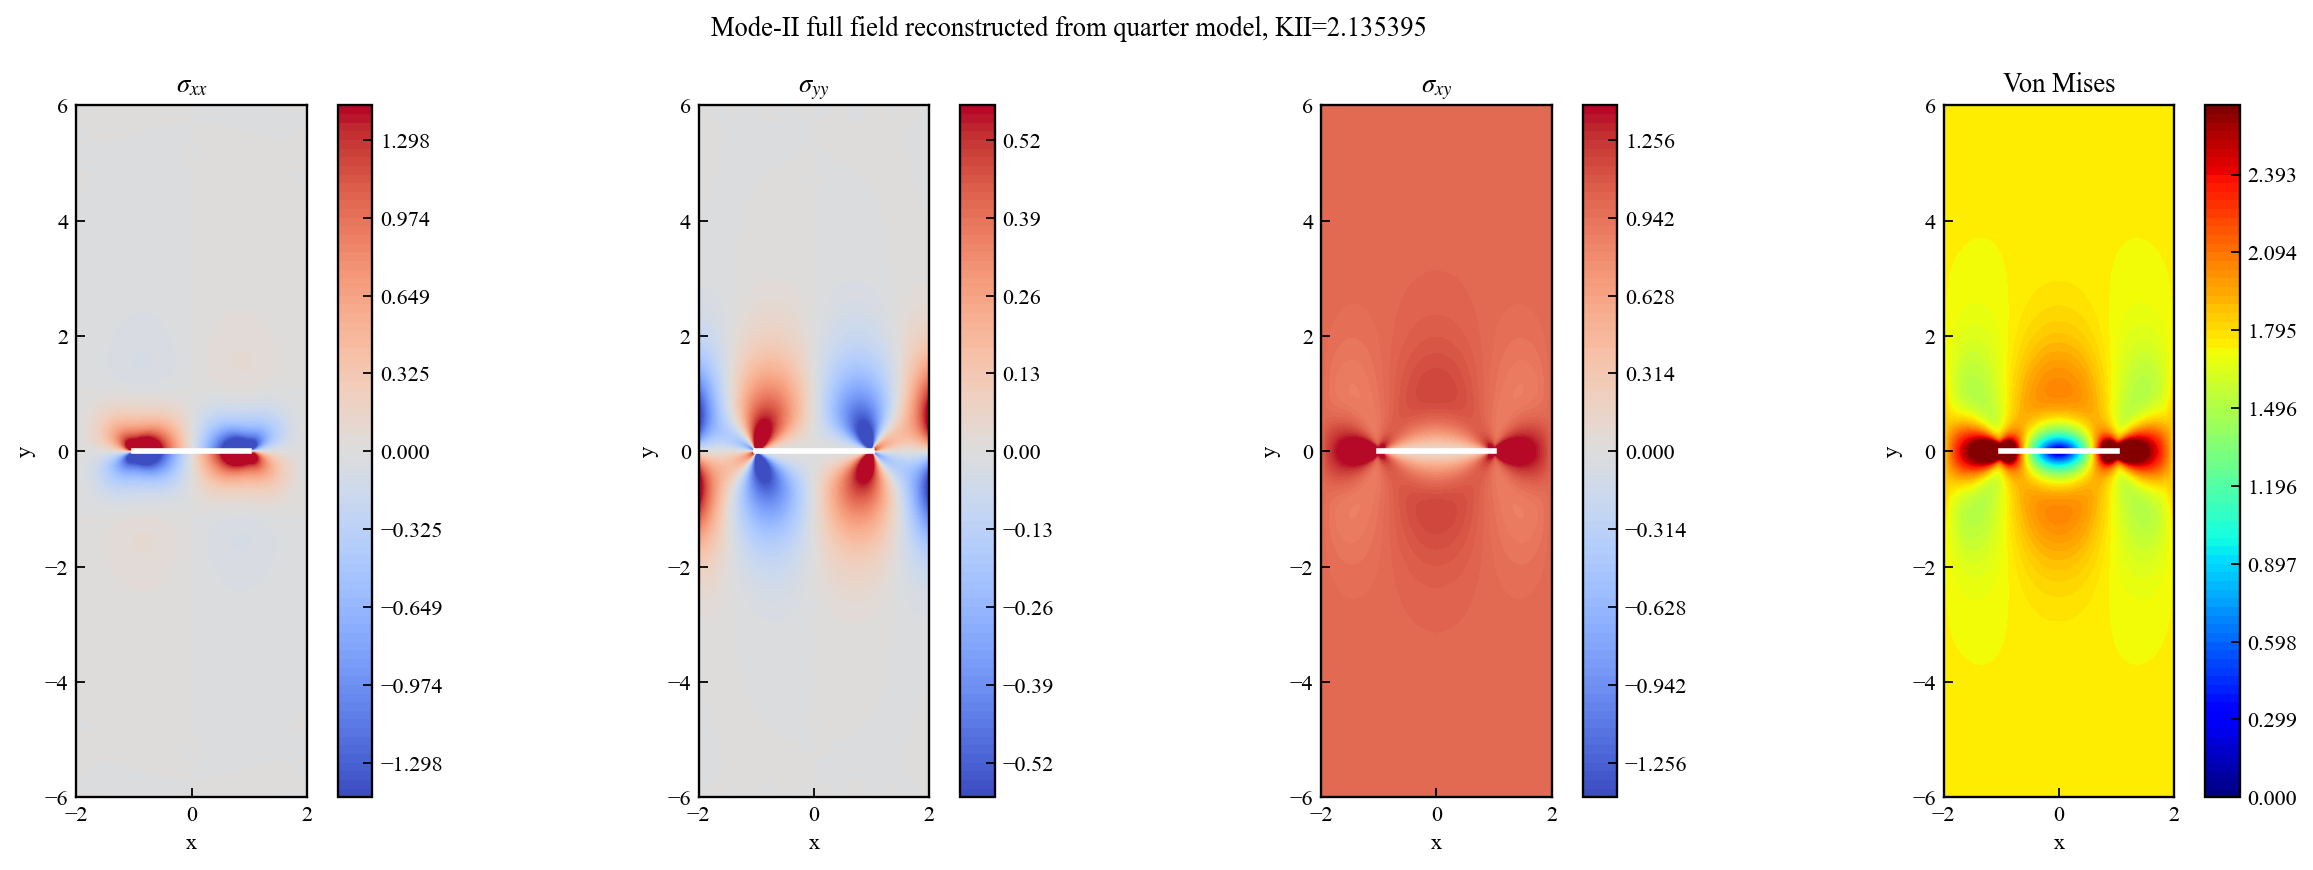

In [140]:
# ============================================================
# Remove the mathematical crack-tip singularity for plotting
# ============================================================

r_right = np.sqrt((X - a)**2 + Y**2)
r_left  = np.sqrt((X + a)**2 + Y**2)

r_tip = np.minimum(r_right, r_left)

# Only for visualization
r_cut = 0.02 * a
tip_mask = r_tip < r_cut


plot_fields = [
    sxx_full.copy(),
    syy_full.copy(),
    sxy_full.copy(),
    von_mises.copy(),
]

for field in plot_fields:
    field[tip_mask] = np.nan


titles = [
    r"$\sigma_{xx}$",
    r"$\sigma_{yy}$",
    r"$\sigma_{xy}$",
    "Von Mises",
]


fig, axes = plt.subplots(
    1, 4,
    figsize=(16, 5.5),
    dpi=160
)

for ax, field, title in zip(
    axes,
    plot_fields,
    titles
):

    vmax = np.nanpercentile(
        np.abs(field),
        99.0
    )

    if title == "Von Mises":

        vmin = 0.0

        # 截断极端值，只影响显示
        field_show = np.clip(field, vmin, vmax)

        levels = np.linspace(
            vmin,
            vmax,
            81
        )

        cf = ax.contourf(
            X,
            Y,
            field_show,
            levels=levels,
            cmap="jet"
        )

    else:

        vmin = -vmax

        # 截断极端值，只影响显示
        field_show = np.clip(field, vmin, vmax)

        levels = np.linspace(
            vmin,
            vmax,
            81
        )

        cf = ax.contourf(
            X,
            Y,
            field_show,
            levels=levels,
            cmap="coolwarm"
        )

    # 普通平头色标
    cbar = fig.colorbar(
        cf,
        ax=ax
    )

    ax.plot(
        [-a, a],
        [0, 0],
        "w-",
        lw=2.5
    )

    ax.set_aspect(
        "equal",
        adjustable="box"
    )

    ax.set_xlabel("x")
    ax.set_ylabel("y")
    ax.set_title(title)

fig.suptitle(
    f"Mode-II full field reconstructed "
    f"from quarter model, KII={KII_pred:.6f}"
)

fig.tight_layout()
plt.show()

## 12. 使用说明

- 默认局部裂尖源只有一圈：`tip_cluster_radii = [0.08]`。
- 如需恢复两圈，只需改为 `tip_cluster_radii = [0.08, 0.16]`。
- 目前每个源点对应两个点力核系数，另加一个 $K_{II}$，因此参数量为 $2N_s+1$。
- 四分之一模型已经把 Mode-II 的反对称性直接写进 `left` 和 `ligament` 边界，不再需要上下双子域、界面连续性和镜像配点。